# Gate diagnostics: competition, position and control capacity

The Newton comparisons show that fusion gains depend on both the task and the encoder combination. This notebook asks whether sequence-level competition, summary information and where a gate acts help explain that variation. It implements the gating comparisons in [the advisor's plan, A.3–A.4](../../docs/Biological_Fusion_Plan.docx), keeping frozen encoder inputs, the BLF codon grid, prediction head and training budget controlled.

The default diagnostics use CoV-Vac RNA chemical degradation and E. coli recombinant protein-production classification. Their targets describe different processes; a useful gate does not identify a biological interaction. CoV-Vac's computed protein representation is not evidence of an established biological reading frame. The [target guide](../../docs/methods/data-and-targets.md) and [Newton encoder-swap results](encoder_swaps.ipynb#Newton-three-seed-findings) explain those limits.

Newton completed 84 new gate fits. The saved diagnostics cover 84 gated fits, including reused MIL baselines. Both encoder combinations were tested on CoV-Vac and E. coli across training seeds 0, 1 and 2. [Read the three-seed comparison](#Read-the-saved-comparison) or [inspect the diagnostic distributions](#Read-gate-variation-and-contribution-scales).

---

## Setup

To refresh this notebook from the returned results, keep `READ_SAVED_RESULTS = True`, leave `RUN_TRAINING`, `RUN_DIAGNOSTICS`, `RUN_ANALYSIS` and `RUN_PARAMETER_PREVIEW` set to `False`, then use **Run All** and **Save**. The CPU reader verifies the files listed in the saved reports and redraws their tables and figures. `BENCHMARK = None` includes both benchmarks. The [root README](../../README.md#notebook-dependencies) lists the notebook dependencies.

In [1]:
# Standard-library paths, immutable configuration updates and saved JSON records.
from dataclasses import asdict, replace
import hashlib
import json
from pathlib import Path
import sys

# Data tables and plotting; import NumPy before PyTorch in the Windows environment.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch

In [2]:
working_dir = Path.cwd().resolve()
for parent in (working_dir, *working_dir.parents):
    if (parent / "shared_code").is_dir():
        CODE_DIR = parent
        break
    if (parent / "Code" / "shared_code").is_dir():
        CODE_DIR = parent / "Code"
        break
else:
    raise FileNotFoundError("Start this notebook from within the repository.")
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from shared_code import datasets
from shared_code.fusion import controlled_experiment as experiment
from shared_code.fusion import correction_experiment, run_identity, study_inputs
from shared_code.fusion import study_references, study_selection, token_embeddings, train

### Execution, comparison settings and locations

The launcher injects one benchmark, seed, verified GPU and output location after the settings cell. CoV-Vac and E. coli are the default panel. Fungal expression is a selectable follow-up; grouped stability needs its own compatible grouped references and remains a held expansion. The source inputs and returned Newton results are never overwritten.

In [3]:
READ_SAVED_RESULTS = True
RUN_TRAINING = False
RUN_ANALYSIS = False
RUN_DIAGNOSTICS = False
RUN_PARAMETER_PREVIEW = False  # Explicit CPU construction from declared shapes; no data or weights.

# The prepared launcher selects one benchmark and one training seed per job.
BENCHMARKS = ("cov_vac_degradation", "ecoli_proteins")
BENCHMARK = None
SEED = 0
TRAINING_SEEDS = (0, 1, 2)
SELECTION_SEED = 0
BOOTSTRAP_DRAWS = 2000
BOOTSTRAP_SEED = 0
BUNDLES = {
    "original": {"dna": "ntv2_100m", "rna": "rnafm", "prot": "esm2_8m"},
    "mrnafm": {"dna": "ntv2_100m", "rna": "mrnafm", "prot": "esm2_8m"},
}

# Retained BLF training budget; these are choices, not newly tuned settings.
BASE_CONFIG = train.TrainConfig(
    lr=3e-5, weight_decay=1e-5, batch_size=32, max_epochs=500,
    early_stopping_patience=20, plateau_patience=5,
    channels=100, tconv="equation", entropy_lambda=0.0, seed=0,
)
CONFIG = replace(BASE_CONFIG, seed=SEED)
PROJECTION_WIDTH = 600
SCORER_WIDTH = 100  # Active for sequence gates; retained but inactive for joint linear gates.
PROJECTION_ACTIVATION = "tanh"
PROJECTION_NORM = "none"
SHARED_SCORER = False
TEMPERATURE_RANGE = (0.02, 20.0)
CONTROL_BOTTLENECK = 2  # Rank of the learned update; the fixed feature path stays full width.
CONTROL_SCALE = 0.5  # Matches independent sigmoid gates at zero logits, not a modality mean.
CONTROL_INITIALIZATION = "zero_output_random_input"
LEGACY_CONTROL_BOTTLENECK = 150  # Preview/history only; not an additional training arm.
N_HEADS = 4
ATTENTION_DROPOUT = 0.1
UPDATE_NORM = "none"  # Nothing renormalizes the anchor after a zero auxiliary update.

DATA_ROOT = CODE_DIR.parent / "datasets"
CACHE_ROOT = CODE_DIR / "stage3" / "embeddings"
REFERENCE_ROOT = CODE_DIR / "stage4" / "results" / "newton_h100_seeds012"
GROUPED_SPLIT_PATH = CODE_DIR / "stage4" / "results" / "grouped_stability_v1" / "split.json"
RESULTS_ROOT = CODE_DIR / "stage4" / "results" / "gate_diagnostics_v1"
DEVICE = "cpu"  # Reading saved records does not inspect or allocate a GPU.
PRODUCER = None  # The launcher supplies observed execution provenance, not an inferred host.

In [4]:
if (CONTROL_BOTTLENECK, CONTROL_SCALE, CONTROL_INITIALIZATION) != (2, 0.5, "zero_output_random_input"):
    raise ValueError("This panel declares the rank-2 half-sum residual control and its initialization explicitly.")
if RUN_PARAMETER_PREVIEW and (RUN_TRAINING or RUN_ANALYSIS or RUN_DIAGNOSTICS):
    raise ValueError("Parameter preview is a separate CPU-only operation.")
if (PROJECTION_WIDTH, SCORER_WIDTH, PROJECTION_ACTIVATION, PROJECTION_NORM,
        SHARED_SCORER, tuple(TEMPERATURE_RANGE)) != (600, 100, "tanh", "none", False, (0.02, 20.0)):
    raise ValueError("This retained reference panel uses the declared BLF projection/scorer settings.")
if TRAINING_SEEDS != (0, 1, 2) or SELECTION_SEED != 0:
    raise ValueError("This panel fixes training seeds 0/1/2 and selection seed 0.")
if RUN_TRAINING == READ_SAVED_RESULTS:
    raise ValueError("Choose saved reading or explicit training, not both/neither.")
if RUN_TRAINING and (RUN_ANALYSIS or RUN_DIAGNOSTICS):
    raise ValueError("Analysis and diagnostic inference are separate from fitting jobs.")
if RUN_TRAINING:
    if BENCHMARK not in BENCHMARKS or SEED not in TRAINING_SEEDS:
        raise ValueError("Select one declared benchmark and training seed for this job.")
    if DEVICE != "cuda" or not torch.cuda.is_available():
        raise RuntimeError("Training requires the verified Newton CUDA device; no CPU fallback.")
    if not isinstance(PRODUCER, dict) or not PRODUCER:
        raise ValueError("Training requires the launcher's observed producer record.")
if RUN_DIAGNOSTICS and (not isinstance(PRODUCER, dict) or not PRODUCER):
    raise ValueError("Explicit best-weight inference requires its own producer record.")
if RUN_DIAGNOSTICS and (BENCHMARK not in BENCHMARKS or SEED not in TRAINING_SEEDS):
    raise ValueError("Select one declared benchmark and seed for diagnostic inference.")
if set(BENCHMARKS) - {"cov_vac_degradation", "ecoli_proteins", "fungal_expression"}:
    raise ValueError("Grouped stability requires a separate grouped-reference adapter; do not reuse supplied-split controls.")
ACTIVE_BENCHMARKS = (BENCHMARK,) if BENCHMARK is not None else BENCHMARKS
if not set(ACTIVE_BENCHMARKS) <= set(BENCHMARKS):
    raise ValueError("The requested benchmark is outside the declared panel.")
CONFIG = replace(BASE_CONFIG, seed=SEED)
if RUN_TRAINING:
    print(f"Explicit {BENCHMARK} seed {SEED} fitting job on {DEVICE}.")
elif RUN_DIAGNOSTICS:
    print(f"Explicit {BENCHMARK} seed {SEED} best-weight diagnostic inference on {DEVICE}.")
elif RUN_ANALYSIS:
    print("Explicit CPU analysis of saved predictions and diagnostics; no fitting or inference.")
else:
    print("Saved-result reading; no fit, inference or statistical analysis is enabled.")

Saved-result reading; no fit, inference or statistical analysis is enabled.


---

## What each comparison changes

The entropy baseline retains BLF's mean-summary softmax and its $\lambda=0.01$ objective. Removing that penalty changes the objective alone. Independent sigmoids let several streams receive large weights simultaneously; their weights are not renormalized and they omit the learned softmax temperature. This comparison tests the declared gate packages, not normalization alone. Mean–max summaries add the strongest activation in each feature alongside its average. Both softmax and sigmoid mean–max variants are declared because the advisor protocol leaves normalization open. The wider summary also increases scorer parameters; inspect that count before attributing a gain only to the summary statistic.

The position gate now uses the joint input in section A.4 of the advisor protocol, $v_t=[H_t^D;H_t^R;H_t^P]$, with $g_{m,t}=\sigma(w_m^\top v_t+b_m)$. Each gate can therefore depend on the other two representations at the same grid position. This replaces the earlier prepared own-stream nonlinear scorer; it does not alter retained BLF fits. The joint sequence comparator applies those same affine scorers to the masked mean of $v_t$, then broadcasts each weight over the valid sequence. Position versus joint sequence changes where weights vary while holding the projected inputs and scorer architecture fixed. Joint sequence versus the retained BLF-style sequence sigmoid separately tests the changed scorer and input context; the older position-versus-BLF-sequence contrast changes both.

The nongated control preserves a full-width fixed feature path and adds a small affine update:

$$
H_t = 0.5\sum_m P_m(x_{m,t}) + W_2(W_1[P_D(x_{D,t});P_R(x_{R,t});P_P(x_{P,t})]+b_1)+b_2.
$$

The projected features $P_m(x_{m,t})$ share width 600; only the learned update passes through rank 2. The fixed half-sum matches independent sigmoid gates at zero logits. The output factor $W_2,b_2$ starts at zero, while the input factor uses ordinary random Linear initialization; the initial update is zero without initializing both factors to zero. This is our agreed reconstruction of the advisor's comparable-parameter nongated control, not a formula specified in her plan.

The update has 5,402 parameters versus 5,403 joint gate parameters, with the same projections and prediction head. Matching those counts does not establish equal functional capacity: the fixed path remains full width, while the learned correction is affine and rank-constrained. This new `position_residual_control` replaces the previous pure rank-150 mixer in the eight-row panel. Its distinct result key prevents legacy weights from being reused as the new method. The earlier control remains a historical/helper option; it is not an extra scheduled A4 fit. No sigmoid variant receives the legacy entropy term.


In [5]:
# Both mean–max variants resolve the plan's unspecified normalization without conflating them.
PANEL = (
    {"key": "mil_entropy", "variant": "sequence_softmax", "entropy": 0.01, "reference": "mil"},
    {"key": "mil_no_entropy", "variant": "sequence_softmax", "entropy": 0.0},
    {"key": "sequence_sigmoid", "variant": "sequence_sigmoid", "entropy": 0.0},
    {"key": "meanmax_softmax", "variant": "sequence_meanmax_softmax", "entropy": 0.0},
    {"key": "meanmax_sigmoid", "variant": "sequence_meanmax_sigmoid", "entropy": 0.0},
    {"key": "joint_sequence_sigmoid", "variant": "joint_sequence_sigmoid", "entropy": 0.0},
    {"key": "position_sigmoid", "variant": "position_sigmoid", "entropy": 0.0},
    {"key": "position_residual_control", "variant": "position_residual_control", "entropy": 0.0},
)
display(pd.DataFrame(PANEL).fillna("new compatible fit"))

,key,variant,entropy,reference
0,mil_entropy,sequence_softmax,0.01,mil
1,mil_no_entropy,sequence_softmax,0.00,new compatible fit
2,sequence_sigmoid,sequence_sigmoid,0.00,new compatible fit
3,meanmax_softmax,sequence_meanmax_softmax,0.00,new compatible fit
4,meanmax_sigmoid,sequence_meanmax_sigmoid,0.00,new compatible fit
5,joint_sequence_sigmoid,joint_sequence_sigmoid,0.00,new compatible fit
6,position_sigmoid,position_sigmoid,0.00,new compatible fit
7,position_residual_control,position_residual_control,0.00,new compatible fit


### Source requirements and choices to inspect

| Component | Source requirement or retained choice | Consequence to check |
| --- | --- | --- |
| Frozen encoders, aligned grid, same prediction head and splits | Advisor protocol A.3–A.5; original and mRNA-FM combinations are our bounded panel | Differences concern these fixed representations, not all encoders |
| Legacy sequence gates | Retained BLF mean/tanh scorer, hidden width 100, independent modality scorers; learned softmax temperature clamped to 0.02–20 | Temperature and feature scale can change gate concentration |
| Projection | Width 600, tanh, no LayerNorm; retained BLF settings | Equal width does not equalize feature norms or biological information |
| TextCNN and training | Channels 100, kernels 3/4/5, dropout 0.2; retained optimizer/stopping budget visible in Setup | Codon and native grids give kernels different biological spans |
| New joint gates | The advisor's linear sigmoid formula; `SCORER_WIDTH` is retained metadata and has no effect here | Compare actual parameter counts; no hidden width tuning |
| Validation selection | Seed-zero validation choice fixed across training seeds 0/1/2 | This is not fully nested model selection or an untouched confirmatory test |

The accepted A4 control uses a fixed half-sum plus rank-2 affine update, with a zero-initialized output factor and a random input factor. This full-width path avoids routing all information through rank 2. The parameter count differs from the joint gate by one, but their functional capacity and inductive bias still differ.

[Advisor protocol A.3–A.5](../../docs/Biological_Fusion_Plan.docx), the [controlled models](../shared_code/fusion/controlled_models.py) and [retained BLF head](../shared_code/fusion/heads.py) identify the source of each operation. [Execution helpers](../shared_code/fusion/controlled_experiment.py) bind the gate formula, settings, rows, targets, partitions and caches before reuse.

The common optimizer and stopping budget is retained for a controlled comparison; it is not independently optimized for each new architecture. Poor performance can therefore reflect optimization sensitivity as well as the fusion operation.


In [6]:
def head_settings(variant, anchor=None):
    settings = {
        "projection_width": PROJECTION_WIDTH,
        "projection_activation": PROJECTION_ACTIVATION,
        "projection_norm": PROJECTION_NORM,
    }
    if variant == "anchor_only":
        return {**settings, "anchor": anchor}
    if variant == "position_control":
        return {**settings, "control_bottleneck": LEGACY_CONTROL_BOTTLENECK}
    if variant == "position_residual_control":
        return {**settings, "control_bottleneck": CONTROL_BOTTLENECK,
                "control_scale": CONTROL_SCALE, "control_initialization": CONTROL_INITIALIZATION}
    settings["scorer_width"] = SCORER_WIDTH
    if variant in experiment.SEQUENCE_VARIANTS:
        normalization = experiment.SEQUENCE_VARIANTS[variant][1]
        settings.update(shared_scorer=SHARED_SCORER,
                        temperature_range=TEMPERATURE_RANGE if normalization == "softmax" else None)
    if variant in experiment.ATTENTION_VARIANTS:
        settings.update(anchor=anchor, n_heads=N_HEADS, dropout=ATTENTION_DROPOUT,
                        update_norm=UPDATE_NORM)
    return settings


def fit_config(seed, entropy=0.0):
    return replace(BASE_CONFIG, seed=seed, entropy_lambda=entropy)


def fit_path(benchmark, bundle, key, seed):
    return RESULTS_ROOT / benchmark / bundle / key / f"seed{seed}.json"


def diagnostic_stem(benchmark, bundle, key, seed):
    return RESULTS_ROOT / benchmark / bundle / "diagnostics-v2" / key / f"seed{seed}"

### Inspect the declared parameter budget before fitting

`RUN_PARAMETER_PREVIEW` is a separate, disabled CPU-only inspection. It constructs heads from declared encoder widths and output counts, restores the random state, and opens no data, cache or weights. Counts describe trainable parameters, not expressivity, throughput or memory. The control bottleneck remains unchanged even if the counts differ.

The prepared residual control preserves the full-width half-sum and restricts only its learned update to rank 2. The table also shows the old pure rank-150 mixer, a pure nearest-count mixer and a direct affine map for structural context. Those alternatives are not additional scheduled fits. Counts alone do not establish equal expressivity or choose a better control.

The total is the registered `requires_grad` count. Anchor-only RNA/protein models currently construct an unused DNA-grid convolution; their total includes it. Fusion and prediction counts are shown separately, and none of these counts measures active gradients or runtime.


In [7]:
if RUN_PARAMETER_PREVIEW:
    from types import SimpleNamespace

    # Checkpoint widths are metadata, not measurements from an opened cache.
    declared_widths = {"ntv2_100m": 512, "rnafm": 640, "mrnafm": 1280, "esm2_8m": 320}
    preview_rows = []
    for bundle, encoders in BUNDLES.items():
        widths = {modality: declared_widths[key] for modality, key in encoders.items()}
        resolutions = {modality: token_embeddings.grid_resolution(key) for modality, key in encoders.items()}
        for entry in PANEL:
            variant = entry["variant"]
            anchors = tuple(encoders) if variant == "anchor_only" or variant in experiment.ATTENTION_VARIANTS else (None,)
            for anchor in anchors:
                stream_shape = SimpleNamespace(widths=widths, resolutions=resolutions, n_outputs=1)
                with torch.random.fork_rng(devices=[]):
                    model = experiment.build_model(stream_shape, variant, fit_config(0, entry["entropy"]),
                                                   settings=head_settings(variant, anchor))
                counts = {label: sum(parameter.numel() for parameter in component.parameters() if parameter.requires_grad)
                          for label, component in (("total", model), ("fusion", model.fusion), ("prediction", model.head))}
                preview_rows.append({"bundle": bundle, "model": entry["key"], "possible anchor": anchor,
                                     "output classes": 1, **counts})
                del model
    display(pd.DataFrame(preview_rows))
    # Count the mixer separately from shared projections and the TextCNN head.
    modality_count, width = len(BUNDLES["original"]), PROJECTION_WIDTH
    gate_parameters = modality_count * (modality_count * width + 1)
    per_rank_parameters = (modality_count + 1) * width + 1
    nearest_rank = max(1, round((gate_parameters - width) / per_rank_parameters))
    structural_options = []
    for label, rank, fixed_width in (
        ("full-width half-sum + rank-2 update (prepared)", CONTROL_BOTTLENECK, width),
        ("pure rank-150 mixer (legacy; not scheduled)", LEGACY_CONTROL_BOTTLENECK, 0),
        ("pure nearest-count mixer (exploratory)", nearest_rank, 0),
    ):
        count = rank * per_rank_parameters + width
        structural_options.append({"option": label, "mixer parameters": count,
                                   "difference from joint gate": count - gate_parameters,
                                   "fixed-path width": fixed_width,
                                   "maximum affine-update rank": min(rank, width)})
    structural_options.append({"option": "direct affine mixer (exploratory)",
                               "mixer parameters": modality_count * width * width + width,
                               "difference from joint gate": modality_count * width * width + width - gate_parameters,
                               "fixed-path width": 0, "maximum affine-update rank": width})
    display(pd.DataFrame(structural_options))
    print(f"Joint gate parameters: {gate_parameters}. The prepared control has a full-width fixed path; rank limits only its learned affine update.")
    print("Regression-output preview only; classification adds 602 readout parameters for three classes. No widths were changed.")
else:
    print("Parameter construction skipped; saved result counts remain available below.")


Parameter construction skipped; saved result counts remain available below.


---

## Reuse references and fix validation choices

Reference readers inspect saved JSON records and preserve the source files in place. During fitting they also verify the actual current rows, targets, partitions and relevant caches. Missing or incompatible references stop the requested comparison; they do not authorize replacement training. A single-encoder reference checks the modality it used, so unchanged DNA/protein singles can be shared across the two bundles.

New fits must also match this notebook's encoder bundle, architecture settings, active modalities and loader contract. A comparison requires consistent recorded implementation sources across its new fits. Reading a legitimate saved result does not require its producer code to match a later reader revision.

In [8]:
def candidate_models(bundle):
    models = ["unimodal:dna", "unimodal:rna"]
    if bundle == "original":
        models.append("unimodal-grid:rna")
    return (*models, "unimodal:prot")


def reference(benchmark, bundle, model, seed, *, streams=None, caches=None):
    config = fit_config(seed, 0.01 if model == "mil" else 0.0)
    return study_references.read_reference(
        REFERENCE_ROOT, benchmark, bundle, model, seed, config,
        streams=streams, cache_records=caches,
    )


def require_reference(benchmark, bundle, model, seed, **kwargs):
    result = reference(benchmark, bundle, model, seed, **kwargs)
    if result is None:
        raise FileNotFoundError(f"Missing compatible reference: {benchmark}/{bundle}/{model}/seed{seed}; no replacement fit.")
    return result

### One selection across the three training seeds

Selection compares only seed-zero validation scores in the declared candidate order, which also breaks ties. A saved selection binds candidate paths and hashes without copying the references. Reading mode reads an existing selection; explicit fitting creates it from compatible evidence before new fits. The test score is never used to choose the anchor.

In [9]:
def selected_anchor(benchmark, bundle, *, write=False, streams=None, caches=None):
    candidates, signatures = [], []
    for model in candidate_models(bundle):
        result = require_reference(benchmark, bundle, model, SELECTION_SEED,
                                   streams=streams, caches=caches)
        source = result.extra_fields["reference_source"]
        candidates.append({"key": model, "modality": model.split(":")[1],
                           "layout": "codon" if model.startswith("unimodal-grid") else "native",
                           "path": source["path"]})
        inputs = result.extra_fields["identity"]["inputs"]
        signatures.append({key: inputs[key] for key in ("rows", "targets", "splits", "split_targets")})
    if any(signature != signatures[0] for signature in signatures[1:]):
        raise ValueError("Anchor candidates do not share the same target rows and partitions.")
    context = {"benchmark": benchmark, "bundle": bundle, "encoders": BUNDLES[bundle],
               "candidate_order": list(candidate_models(bundle)), "inputs": signatures[0]}
    path = RESULTS_ROOT / benchmark / bundle / "anchor-selection.json"
    if write:
        return study_selection.select_anchor(candidates, path=path, context=context,
                                             evidence_root=REFERENCE_ROOT)
    if not path.is_file():
        return None
    return study_selection.read_anchor(path, context=context, evidence_root=REFERENCE_ROOT)

In [10]:
def saved_new_fit(benchmark, bundle, entry, seed):
    path = fit_path(benchmark, bundle, entry["key"], seed)
    if not path.is_file():
        return None
    anchor = None
    if entry["variant"] == "anchor_only" or entry["variant"] in experiment.ATTENTION_VARIANTS:
        choice = selected_anchor(benchmark, bundle)
        if choice is None:
            raise FileNotFoundError("The saved attention fit requires its fixed validation anchor selection.")
        anchor = choice["modality"]
    return experiment.read_panel_fit(
        path, benchmark=benchmark, variant=entry["variant"],
        config=fit_config(seed, entry["entropy"]), encoders=BUNDLES[bundle],
        settings=head_settings(entry["variant"], anchor),
    )


def fit_source(benchmark, bundle, entry, seed):
    if entry.get("reference"):
        result = reference(benchmark, bundle, entry["reference"], seed)
        path = None if result is None else Path(result.extra_fields["reference_source"]["path"])
    else:
        result = saved_new_fit(benchmark, bundle, entry, seed)
        path = fit_path(benchmark, bundle, entry["key"], seed)
    return result, path

### Inventory what is available

This table reads saved records only. A row labeled missing is pending work, not a request to compute it. The three-seed analysis below requires a complete declared panel and identical test rows; it does not average whichever seeds happen to be available.

In [11]:
coverage = []
for benchmark in ACTIVE_BENCHMARKS:
    for bundle in BUNDLES:
        for entry in PANEL:
            for seed in TRAINING_SEEDS:
                result, path = fit_source(benchmark, bundle, entry, seed)
                coverage.append({"benchmark": benchmark, "bundle": bundle,
                                 "model": entry["key"], "seed": seed,
                                 "status": "saved reference" if result is not None and entry.get("reference")
                                           else "saved" if result is not None else "missing",
                                 "test score": None if result is None else result.test_score})
display(pd.DataFrame(coverage))
print("Saved records are read in place. Current input/cache checks happen only in explicit execution.")

,benchmark,bundle,model,seed,status,test score
0,cov_vac_degradation,original,mil_entropy,0,saved reference,0.784345
1,cov_vac_degradation,original,mil_entropy,1,saved reference,0.776880
2,cov_vac_degradation,original,mil_entropy,2,saved reference,0.775951
3,cov_vac_degradation,original,mil_no_entropy,0,saved,0.792216
4,cov_vac_degradation,original,mil_no_entropy,1,saved,0.789229
...,...,...,...,...,...,...
91,ecoli_proteins,mrnafm,position_sigmoid,1,saved,0.580056
92,ecoli_proteins,mrnafm,position_sigmoid,2,saved,0.566011
93,ecoli_proteins,mrnafm,position_residual_control,0,saved,0.580056
94,ecoli_proteins,mrnafm,position_residual_control,1,saved,0.592697


Saved records are read in place. Current input/cache checks happen only in explicit execution.


---

## Fit the declared comparison

This path opens only verified, already-complete token caches. It performs no encoder downloads or extraction. Each completed compatible fit is reused, interrupted checkpoints follow the existing recovery contract, and incompatible completed results are preserved. The context manager closes owned caches even if a fit fails.

Newton completed seven new heads for each benchmark, encoder combination and seed (84 fits). The report also uses 12 existing entropy-regularized MIL fits and the appropriate concatenation and single-encoder references. Best-weight inference produced 84 gated-fit diagnostic records. The nongated control has no gates to inspect.

In [12]:
def run_context(benchmark, bundle):
    verification = token_embeddings.CacheVerification()
    with study_inputs.open_streams(
        benchmark, BUNDLES[bundle], DATA_ROOT, CACHE_ROOT,
        stability_split=GROUPED_SPLIT_PATH, verification=verification,
    ) as (streams, caches, groups, positions, split_identity):
        # References must match this cohort before the first new fit.
        require_reference(benchmark, bundle, "concat", SEED, streams=streams, caches=caches)
        choice = selected_anchor(benchmark, bundle, write=True, streams=streams, caches=caches)
        require_reference(benchmark, bundle, choice["key"], SEED, streams=streams, caches=caches)
        for entry in PANEL:
            config = fit_config(SEED, entry["entropy"])
            if entry.get("reference"):
                require_reference(benchmark, bundle, entry["reference"], SEED,
                                  streams=streams, caches=caches)
                continue
            path = fit_path(benchmark, bundle, entry["key"], SEED)
            experiment.run_fit(
                streams, entry["variant"], config, head_settings(entry["variant"], choice["modality"]),
                caches, path.parent, DEVICE, PRODUCER, path.stem,
            )

In [13]:
if RUN_TRAINING:
    for bundle in BUNDLES:
        run_context(BENCHMARK, bundle)
else:
    print("Fitting disabled. Missing results remain missing.")

Fitting disabled. Missing results remain missing.


---

## Preserve per-example diagnostic evidence

Newton's diagnostic inference used the verified best weights to record test-row gates at valid positions, along with the norms of projected streams, weighted contributions and the fused representation. The reused MIL fits retain their original BLF identities.

A gate's weight and the magnitude of its contribution answer different questions. Softmax distributes a total weight of one among the streams. Independent sigmoid gates can also change the overall scale of the fused representation.

Each Newton diagnostic job covered one benchmark and seed across both encoder combinations. The completed three-seed distributions are available below. Older gate-only records lack the norms needed for contribution-scale comparisons.

In [14]:
def collect_context_diagnostics(benchmark, bundle, seed):
    with study_inputs.open_streams(
        benchmark, BUNDLES[bundle], DATA_ROOT, CACHE_ROOT,
        stability_split=GROUPED_SPLIT_PATH,
    ) as (streams, caches, groups, positions, split_identity):
        choice = selected_anchor(benchmark, bundle, streams=streams, caches=caches)
        if choice is None:
            raise FileNotFoundError("The study's fixed validation selection has not been saved.")
        for entry in PANEL:
            if entry["variant"] in ("anchor_only", "position_control", "position_residual_control"):
                continue  # These controls have no routing weights to collect.
            config = fit_config(seed, entry["entropy"])
            stem = diagnostic_stem(benchmark, bundle, entry["key"], seed)
            if entry.get("reference"):
                study_references.collect_reference_diagnostics(
                    REFERENCE_ROOT, benchmark, bundle, seed, config, streams=streams,
                    cache_records=caches, output_stem=stem, device=DEVICE, producer=PRODUCER,
                )
            else:
                experiment.collect_diagnostics(
                    streams, entry["variant"], config, head_settings(entry["variant"], choice["modality"]),
                    caches, result_path=fit_path(benchmark, bundle, entry["key"], seed),
                    output_stem=stem, device=DEVICE, producer=PRODUCER,
                )

In [15]:
if RUN_DIAGNOSTICS:
    for bundle in BUNDLES:
        collect_context_diagnostics(BENCHMARK, bundle, SEED)
else:
    print("Best-weight inference disabled; saved scores do not recreate gate diagnostics.")

Best-weight inference disabled; saved scores do not recreate gate diagnostics.


---

## Compare complete results

Explicit analysis loads the retained CSV to verify ordered rows, targets and partitions against every saved fit; it never opens embedding caches. It reports each seed, their mean and sample standard deviation, and paired 95% intervals obtained by resampling whole exact-sequence groups. All three seeds are averaged inside each draw. The interval addresses test-group sampling for these fixed fits; the seed standard deviation describes training variability. Neither estimates performance on a different species or experimental condition.

The main contrasts use identical-input concatenation and the fixed validation-selected single. The gate panel also isolates entropy removal and the position gate versus its nongated control. All comparisons, including failures to improve, remain in the report; the intervals are unadjusted for the multiple comparisons.

Parameter counts come from each new fit's bound model identity, rather than an assumed match. Historical references without a recorded count are shown as missing, not guessed. The completed report binds source files and analysis settings, and is never silently overwritten.

Direct mechanism contrasts compare the declared normalization, summary, positional or residual changes. They use the same completed fits; they do not expand the training panel. The position-versus-joint-sequence contrast keeps scorer form and count fixed. Comparisons with the legacy BLF sequence gate also change scorer structure and input context; equal parameter counts do not establish equal functional capacity.


In [16]:
def source_record(path):
    path = Path(path).resolve()
    for role, root in (("study", RESULTS_ROOT), ("reference", REFERENCE_ROOT), ("dataset", DATA_ROOT)):
        root = Path(root).resolve()
        if path.is_relative_to(root):
            return f"{role}/{path.relative_to(root).as_posix()}", hashlib.sha256(path.read_bytes()).hexdigest()
    raise ValueError("A comparison source is outside the declared evidence roots.")


def verify_report_sources(report):
    score_schemas = ("controlled-fusion-three-seed-v1", "controlled-fusion-three-seed-v2",
                     "controlled-fusion-three-seed-v3", "controlled-fusion-three-seed-v4")
    gate_schemas = ("controlled-gate-distributions-v1", "controlled-gate-distributions-v2", "controlled-gate-distributions-v3")
    if report.get("schema") not in (*score_schemas, *gate_schemas) or report.get("seeds") != list(TRAINING_SEEDS):
        raise ValueError("Saved report belongs to a different comparison contract.")
    if report["schema"] in score_schemas:
        expected_bootstrap = {"draws": BOOTSTRAP_DRAWS, "seed": BOOTSTRAP_SEED,
                              "sampling_unit": "exact nucleotide sequence group",
                              "seeds_averaged_within_draw": list(TRAINING_SEEDS)}
        if report.get("bootstrap") != expected_bootstrap:
            raise ValueError("Saved report uses different interval settings.")
    roots = {"study": RESULTS_ROOT, "reference": REFERENCE_ROOT, "dataset": DATA_ROOT}
    for name, checksum in report["sources"].items():
        role, relative = name.split("/", 1)
        if role not in roots:
            raise ValueError("Unknown report evidence role.")
        root = Path(roots[role]).resolve()
        path = (root / relative).resolve()
        if not path.is_relative_to(root) or hashlib.sha256(path.read_bytes()).hexdigest() != checksum:
            raise ValueError("A saved report source is missing, changed or outside its evidence root.")


In [17]:
def comparison_rows():
    rows, sources = [], {}
    implementation_sources = None
    for benchmark in ACTIVE_BENCHMARKS:
        for bundle in BUNDLES:
            choice = selected_anchor(benchmark, bundle)
            if choice is None:
                raise FileNotFoundError("Save the validation-only anchor choice before comparisons.")
            selection_path = RESULTS_ROOT / benchmark / bundle / "anchor-selection.json"
            name, checksum = source_record(selection_path)
            sources[name] = checksum
            for seed in TRAINING_SEEDS:
                concat = require_reference(benchmark, bundle, "concat", seed)
                single = require_reference(benchmark, bundle, choice["key"], seed)
                for baseline in (concat, single):
                    source = baseline.extra_fields["reference_source"]
                    name, checksum = source_record(source["path"])
                    sources[name] = checksum
                for entry in PANEL:
                    result, path = fit_source(benchmark, bundle, entry, seed)
                    if result is None:
                        raise FileNotFoundError(f"Complete the declared panel before analysis: {path}")
                    if not entry.get("reference"):
                        recorded = result.extra_fields["identity"]["model"]["implementation_sha256"]
                        if implementation_sources is None:
                            implementation_sources = recorded
                        elif recorded != implementation_sources:
                            raise ValueError("New panel fits use different recorded implementation sources; report separately.")
                    for baseline in (concat, single):
                        if result.test_truth != baseline.test_truth:
                            raise ValueError("Comparisons require identical ordered test targets.")
                        first = result.extra_fields["identity"]["inputs"]
                        second = baseline.extra_fields["identity"]["inputs"]
                        if any(first[key] != second[key] for key in ("rows", "targets", "splits", "split_targets")):
                            raise ValueError("Comparison input identities differ.")
                    name, checksum = source_record(path)
                    sources[name] = checksum
                    rows.append({"benchmark": benchmark, "bundle": bundle, "model": entry["key"],
                                 "seed": seed, "score": result.test_score,
                                 "trainable parameters": result.extra_fields["identity"]["model"].get("parameter_counts", {}).get("total"),
                                 "fusion parameters": result.extra_fields["identity"]["model"].get("parameter_counts", {}).get("fusion"), "selected single": choice["key"],
                                 "minus concat": result.test_score - concat.test_score,
                                 "minus selected single": result.test_score - single.test_score})
    return rows, sources

In [18]:
def mechanism_contrasts():
    """Direct planned contrasts; they add reporting comparisons, not new fits."""
    return [
        ('sequence_sigmoid minus mil_no_entropy', 'sequence_sigmoid', 'mil_no_entropy'),
        ('meanmax_softmax minus mil_no_entropy', 'meanmax_softmax', 'mil_no_entropy'),
        ('meanmax_sigmoid minus sequence_sigmoid', 'meanmax_sigmoid', 'sequence_sigmoid'),
        ('joint_sequence_sigmoid minus sequence_sigmoid', 'joint_sequence_sigmoid', 'sequence_sigmoid'),
        ('position_sigmoid minus joint_sequence_sigmoid', 'position_sigmoid', 'joint_sequence_sigmoid'),
        ('position_sigmoid minus sequence_sigmoid', 'position_sigmoid', 'sequence_sigmoid'),
    ]


In [19]:
def comparison_intervals():
    intervals, sources = [], {}
    for benchmark in ACTIVE_BENCHMARKS:
        rows, split_column, groups, positions, split_identity = study_inputs.benchmark_rows(
            benchmark, DATA_ROOT,
            stability_split=GROUPED_SPLIT_PATH if benchmark == "mrna_stability" else None,
        )
        source = DATA_ROOT / datasets.DATASETS[benchmark].path
        name, checksum = source_record(source)
        sources[name] = checksum
        task = datasets.DATASETS[benchmark].task
        for bundle in BUNDLES:
            choice = selected_anchor(benchmark, bundle)
            if choice is None:
                raise FileNotFoundError("Save the validation-only anchor choice first.")
            records = {
                "concat": {seed: require_reference(benchmark, bundle, "concat", seed) for seed in TRAINING_SEEDS},
                "selected_single": {seed: require_reference(benchmark, bundle, choice["key"], seed) for seed in TRAINING_SEEDS},
            }
            for entry in PANEL:
                records[entry["key"]] = {
                    seed: fit_source(benchmark, bundle, entry, seed)[0] for seed in TRAINING_SEEDS
                }
                if any(result is None for result in records[entry["key"]].values()):
                    raise FileNotFoundError("Complete the entire declared panel before bootstrap analysis.")
            comparisons = [(f"{entry['key']} minus {baseline}", entry["key"], baseline)
                           for entry in PANEL for baseline in ("concat", "selected_single")]
            if "anchor_only" in records:
                comparisons.extend((f"{entry['key']} minus anchor_only", entry["key"], "anchor_only")
                                   for entry in PANEL if entry["key"] != "anchor_only")
            else:
                comparisons.extend((
                    ("mil_no_entropy minus mil_entropy", "mil_no_entropy", "mil_entropy"),
                    ("position_sigmoid minus position_residual_control", "position_sigmoid", "position_residual_control"),
                ))
            comparisons.extend(mechanism_contrasts())
            measured = experiment.paired_intervals(
                records, rows=rows, split_column=split_column, task=task, groups=groups,
                seeds=TRAINING_SEEDS, comparisons=comparisons,
                draws=BOOTSTRAP_DRAWS, bootstrap_seed=BOOTSTRAP_SEED,
            )
            intervals.extend({"benchmark": benchmark, "bundle": bundle, **row} for row in measured)
    return intervals, sources


In [20]:
REPORT_PATH = RESULTS_ROOT / "reports" / "three-seed-comparison-v4.json"
if RUN_ANALYSIS:
    comparison, sources = comparison_rows()
    intervals, cohort_sources = comparison_intervals()
    sources.update(cohort_sources)
    frame = pd.DataFrame(comparison)
    summaries = []
    for (benchmark, bundle, model), rows in frame.groupby(["benchmark", "bundle", "model"], sort=False):
        if set(rows["seed"]) != set(TRAINING_SEEDS) or len(rows) != len(TRAINING_SEEDS):
            raise ValueError("No partial-seed averaging.")
        counts = {}
        for field in ("trainable parameters", "fusion parameters"):
            observed = rows[field].dropna().unique()
            if len(observed) > 1:
                raise ValueError("Parameter counts differ across the declared seeds.")
            counts[field] = int(observed[0]) if len(observed) else None
        summaries.append({**counts, "benchmark": benchmark, "bundle": bundle, "model": model,
                          "mean score": float(rows["score"].mean()),
                          "seed SD": float(rows["score"].std(ddof=1)),
                          "mean minus concat": float(rows["minus concat"].mean()),
                          "mean minus selected single": float(rows["minus selected single"].mean())})
    report = {"schema": "controlled-fusion-three-seed-v4", "seeds": list(TRAINING_SEEDS),
              "sources": sources, "mechanism_contrasts": [list(item) for item in mechanism_contrasts()], "per_seed": comparison, "summary": summaries,
              "paired_intervals": intervals,
              "bootstrap": {"draws": BOOTSTRAP_DRAWS, "seed": BOOTSTRAP_SEED,
                            "sampling_unit": "exact nucleotide sequence group",
                            "seeds_averaged_within_draw": list(TRAINING_SEEDS)},
              "analysis_source_sha256": {
                  Path(module.__file__).name: hashlib.sha256(Path(module.__file__).read_bytes()).hexdigest()
                  for module in (experiment, train, study_inputs)
              },
              "analysis_notebook_sha256": hashlib.sha256(
                  (CODE_DIR / "stage4" / "gate_diagnostics.ipynb").read_bytes()).hexdigest()}
    if REPORT_PATH.is_file():
        if json.loads(REPORT_PATH.read_text(encoding="utf-8")) != report:
            raise ValueError("A different completed report exists; preserve it and choose a new analysis destination.")
    else:
        correction_experiment._publish(REPORT_PATH, report)
else:
    previous_report = RESULTS_ROOT / "reports" / "three-seed-comparison-v3.json"
    if not previous_report.is_file():
        previous_report = RESULTS_ROOT / "reports" / "three-seed-comparison-v2.json"
    legacy_report = previous_report if previous_report.is_file() else RESULTS_ROOT / "reports" / "three-seed-comparison.json"
    read_path = REPORT_PATH if REPORT_PATH.is_file() else legacy_report
    report = json.loads(read_path.read_text(encoding="utf-8")) if read_path.is_file() else None
    if report is not None and read_path == legacy_report:
        print("Historical report: it predates the matched joint sequence/position panel; inspect its recorded model keys. No recalculation.")
    print("No saved three-seed report." if report is None else "Reading the saved three-seed report.")
if report is not None:
    verify_report_sources(report)

Reading the saved three-seed report.


### Read the saved comparison

The plots compare each head with simple concatenation using the same encoder combination. Zero on the horizontal axis means equal mean test scores. For the effect of gate position, read `position_sigmoid minus joint_sequence_sigmoid` in the paired-interval table. These models share the same inputs and scorer, while the sequence gate uses one weight per modality for the whole sequence. CoV-Vac differences use Spearman correlation. E. coli differences use accuracy on a 0–1 scale, where 0.01 equals one percentage point. [Saved comparisons](results/gate_diagnostics_v1/reports/three-seed-comparison-v4.json)

,benchmark,bundle,fusion parameters,mean minus concat,mean minus selected single,mean score,model,seed SD,trainable parameters
0,cov_vac_degradation,original,NaN,-0.012826,-0.058276,0.779059,mil_entropy,0.004601,NaN
1,cov_vac_degradation,original,1245701.0,-0.008553,-0.054002,0.783332,mil_no_entropy,0.012888,2491102.0
2,cov_vac_degradation,original,1245700.0,0.038858,-0.006591,0.830743,sequence_sigmoid,0.002690,2491101.0
3,cov_vac_degradation,original,1605701.0,0.000521,-0.044928,0.792406,meanmax_softmax,0.008648,2851102.0
4,cov_vac_degradation,original,1605700.0,0.039355,-0.006095,0.831240,meanmax_sigmoid,0.002652,2851101.0
5,cov_vac_degradation,original,890403.0,0.039897,-0.005552,0.831782,joint_sequence_sigmoid,0.004860,2135804.0
6,cov_vac_degradation,original,890403.0,0.039604,-0.005845,0.831489,position_sigmoid,0.004688,2135804.0
7,cov_vac_degradation,original,890402.0,0.015371,-0.030079,0.807256,position_residual_control,0.011265,2135803.0
8,cov_vac_degradation,mrnafm,NaN,-0.002642,-0.061394,0.758752,mil_entropy,0.008802,NaN
9,cov_vac_degradation,mrnafm,1629701.0,-0.002068,-0.060820,0.759326,mil_no_entropy,0.008949,2875102.0


,benchmark,bundle,ci_high,ci_low,comparison,difference,first_wins,groups,rows
0,cov_vac_degradation,original,0.009300,-0.036260,mil_entropy minus concat,-0.012826,0.1350,400,400
1,cov_vac_degradation,original,-0.021695,-0.097072,mil_entropy minus selected_single,-0.058276,0.0000,400,400
2,cov_vac_degradation,original,0.010343,-0.027329,mil_no_entropy minus concat,-0.008553,0.1820,400,400
3,cov_vac_degradation,original,-0.019423,-0.088393,mil_no_entropy minus selected_single,-0.054002,0.0005,400,400
4,cov_vac_degradation,original,0.049429,0.029042,sequence_sigmoid minus concat,0.038858,1.0000,400,400
...,...,...,...,...,...,...,...,...,...
91,ecoli_proteins,mrnafm,0.013109,-0.019675,meanmax_softmax minus mil_no_entropy,-0.003277,0.3375,712,712
92,ecoli_proteins,mrnafm,0.006554,-0.021536,meanmax_sigmoid minus sequence_sigmoid,-0.007022,0.1495,712,712
93,ecoli_proteins,mrnafm,0.007491,-0.017322,joint_sequence_sigmoid minus sequence_sigmoid,-0.004682,0.2175,712,712
94,ecoli_proteins,mrnafm,0.014045,-0.005150,position_sigmoid minus joint_sequence_sigmoid,0.004682,0.8300,712,712


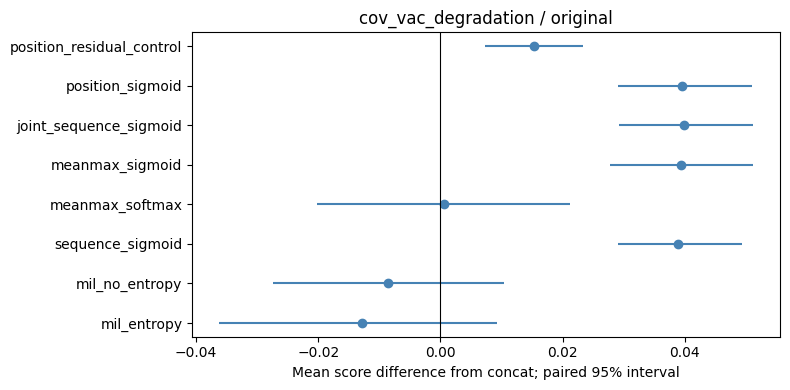

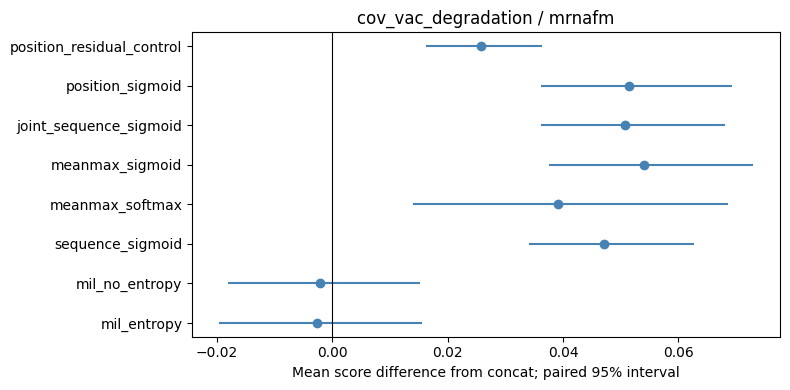

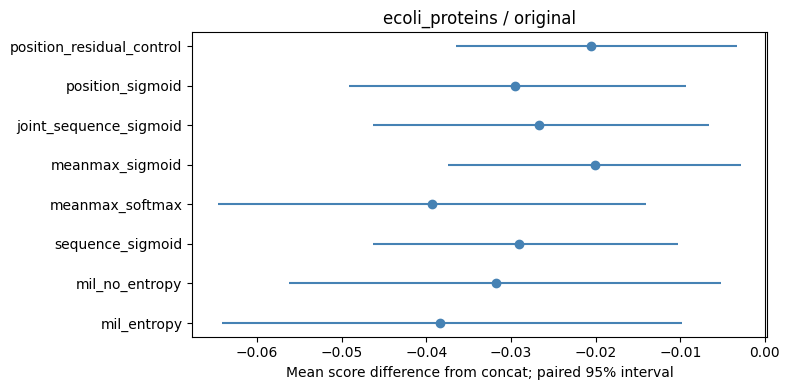

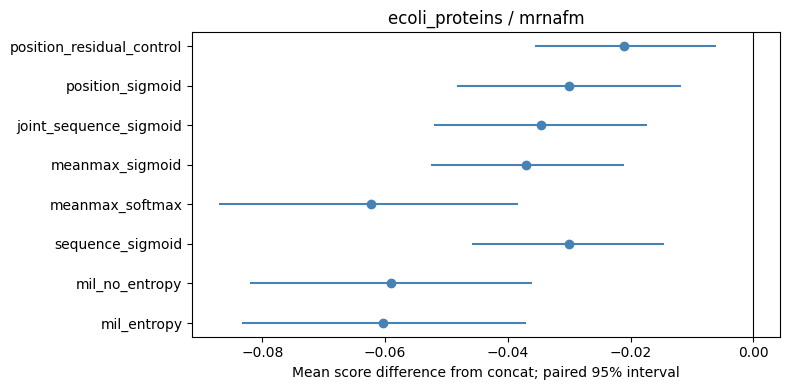

In [21]:
if report is not None:
    summaries = pd.DataFrame(report["summary"])
    intervals = pd.DataFrame(report["paired_intervals"])
    display(summaries)
    display(intervals)
    for (benchmark, bundle), rows in summaries.groupby(["benchmark", "bundle"], sort=False):
        compared = intervals[(intervals["benchmark"] == benchmark) & (intervals["bundle"] == bundle)]
        compared = compared.set_index("comparison").loc[[f"{model} minus concat" for model in rows["model"]]]
        positions = np.arange(len(rows))
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.hlines(positions, compared["ci_low"], compared["ci_high"], color="steelblue")
        ax.scatter(compared["difference"], positions, color="steelblue")
        ax.set_yticks(positions, rows["model"])
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set(title=f"{benchmark} / {bundle}", xlabel="Mean score difference from concat; paired 95% interval")
        fig.tight_layout()
        plt.show()

### Read gate variation and contribution scales

The plots read the saved CPU summary of Newton's per-example diagnostics. Each transcript contributes equally. Between-transcript quartiles describe the distribution of mean weights. For positional gates, the within-transcript standard deviation and range describe how much the weights change along one sequence. [Saved diagnostic distributions](results/gate_diagnostics_v1/reports/gate-distributions-v3.json)

The norm table summarizes the average magnitude over valid positions in each transcript, then takes quartiles across transcripts. Read these magnitudes alongside the gate weights and, for softmax gates, the learned temperature.

The report records the validation-selected single modality beside each diagnostic row and the sum of modality weights. Softmax mass is one; independent sigmoid mass can change overall amplitude. A low gate does not yet establish harmful suppression of the selected single encoder. Join these patterns to the complete score contrasts before choosing any perturbation experiment. Region/auxiliary shuffling or clamping remains a separately proposed inference control, not an additional mandatory training arm.

[Attention is not Explanation](../../docs/sources.md#jain-and-wallace-attention-is-not-explanation) provides a methodological caution from specific NLP models. These contribution measurements address numerical scale, not biological causality.

In [22]:
def summarize_saved_gates():
    entries = [entry for entry in PANEL if entry["variant"] in experiment.SEQUENCE_VARIANTS
               or entry["variant"] in ("joint_sequence_sigmoid", "position_sigmoid") or entry["variant"] in experiment.ATTENTION_VARIANTS]
    requests = [(benchmark, bundle, entry, seed) for benchmark in ACTIVE_BENCHMARKS
                for bundle in BUNDLES for entry in entries for seed in TRAINING_SEEDS]
    missing = [str(diagnostic_stem(b, c, e["key"], s)) for b, c, e, s in requests
               if not Path(str(diagnostic_stem(b, c, e["key"], s)) + ".json").is_file()]
    if missing:
        return None, missing
    report = {"schema": "controlled-gate-distributions-v3", "seeds": list(TRAINING_SEEDS),
              "sources": {},
              "analysis_source_sha256": hashlib.sha256(Path(experiment.__file__).read_bytes()).hexdigest(),
              "summary_rule": "equal-transcript means; within-row population SD/range; between-row quartiles",
              "summary": [], "positional_variation": [], "norm_summary": [],
              "update_anchor_ratios": [], "weight_mass": [], "diagnostic_status": []}
    for benchmark, bundle, entry, seed in requests:
        stem = diagnostic_stem(benchmark, bundle, entry["key"], seed)
        record, arrays = experiment.read_diagnostics(stem)
        result, fit_file = fit_source(benchmark, bundle, entry, seed)
        if result is None or record["identity"]["fit_sha256"] != hashlib.sha256(fit_file.read_bytes()).hexdigest():
            raise ValueError("Diagnostics do not identify the saved comparison fit.")
        for path in (fit_file, Path(str(stem) + ".json"), Path(str(stem) + ".npz")):
            source, checksum = source_record(path)
            report["sources"][source] = checksum
        choice = selected_anchor(benchmark, bundle)
        if choice is None:
            raise FileNotFoundError("Saved gate interpretation requires the fixed validation selection.")
        selection = RESULTS_ROOT / benchmark / bundle / "anchor-selection.json"
        source, checksum = source_record(selection)
        report["sources"][source] = checksum
        context = {"benchmark": benchmark, "bundle": bundle, "model": entry["key"], "seed": seed,
                   "selected single modality": choice["modality"]}
        measured = experiment.summarize_diagnostics(record, arrays)
        for quantity in ("summary", "positional_variation", "norm_summary", "update_anchor_ratios", "weight_mass"):
            report[quantity].extend({**context, **row} for row in measured[quantity])
        report["diagnostic_status"].append({**context, "norm status": measured["norm_status"],
                                             "temperature": measured["temperature"]})
    return report, []


In [23]:
GATE_REPORT_PATH = RESULTS_ROOT / "reports" / "gate-distributions-v3.json"
if RUN_ANALYSIS:
    gate_report, missing_diagnostics = summarize_saved_gates()
    if gate_report is None:
        print(f"Gate-distribution analysis held: {len(missing_diagnostics)} missing diagnostic records; no inference started.")
    elif GATE_REPORT_PATH.is_file():
        if json.loads(GATE_REPORT_PATH.read_text(encoding="utf-8")) != gate_report:
            raise ValueError("A different completed gate report exists; preserve it.")
    else:
        correction_experiment._publish(GATE_REPORT_PATH, gate_report)
else:
    previous_report = RESULTS_ROOT / "reports" / "gate-distributions-v2.json"
    legacy_report = previous_report if previous_report.is_file() else RESULTS_ROOT / "reports" / "gate-distributions.json"
    read_path = GATE_REPORT_PATH if GATE_REPORT_PATH.is_file() else legacy_report
    gate_report = json.loads(read_path.read_text(encoding="utf-8")) if read_path.is_file() else None
    if gate_report is not None and read_path == legacy_report:
        print("Historical gate report: the matched joint sequence/position panel was not required; inspect its recorded model keys.")
if gate_report is not None:
    verify_report_sources(gate_report)

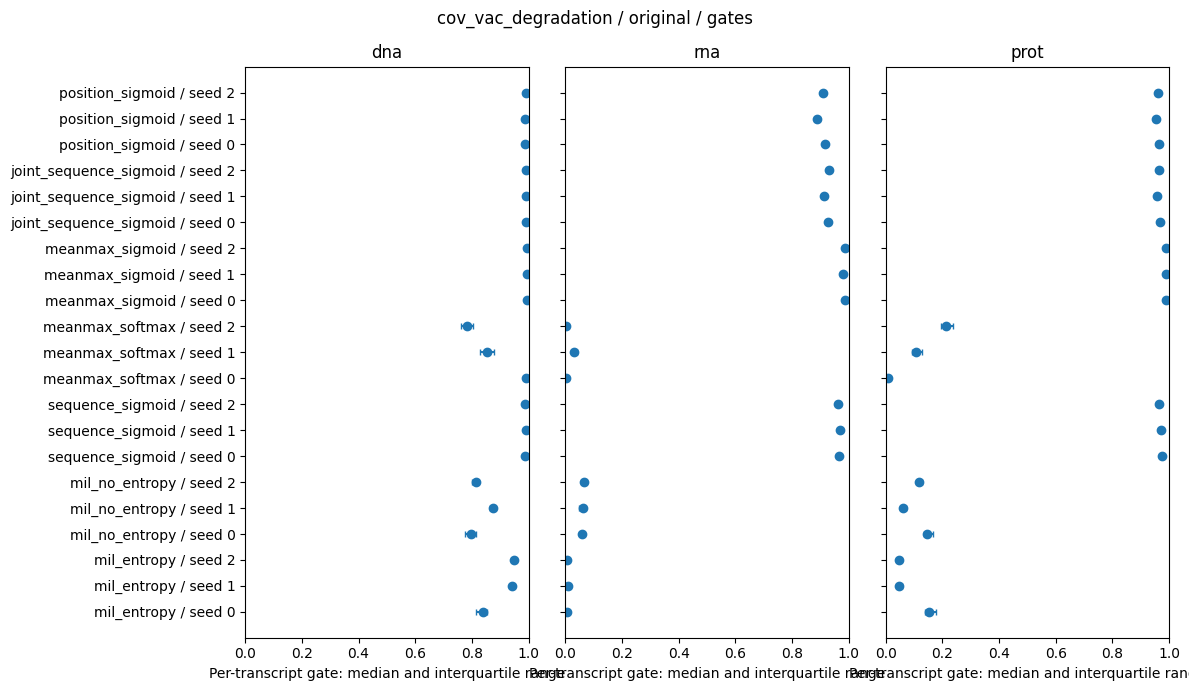

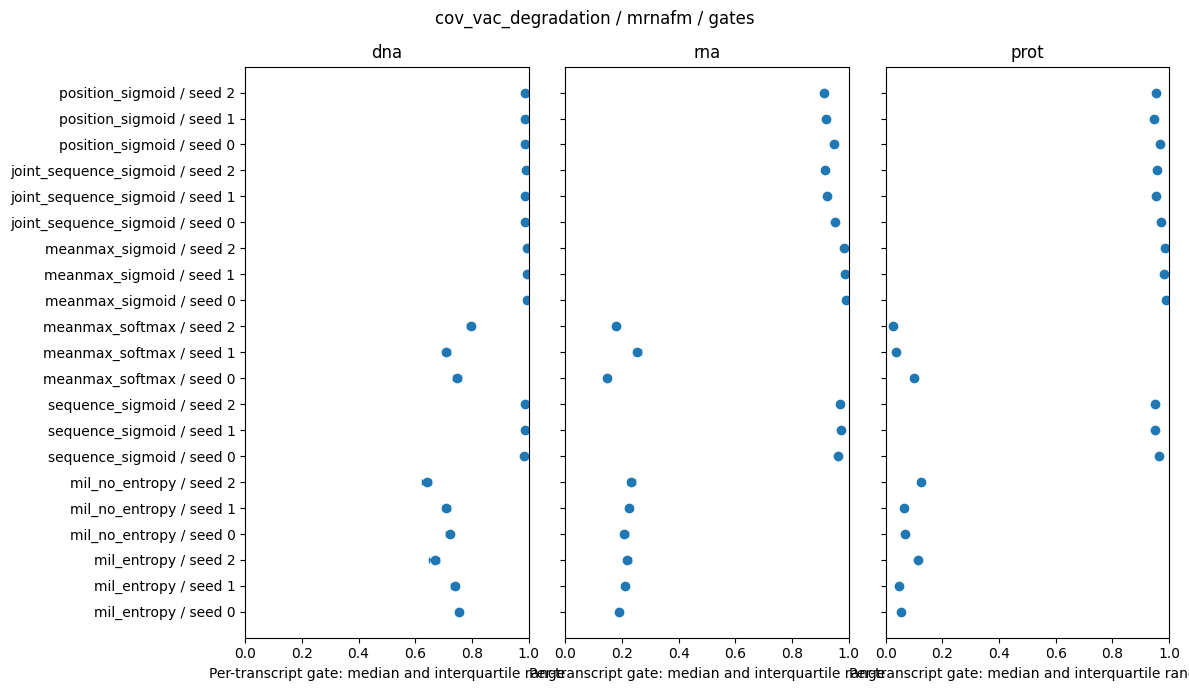

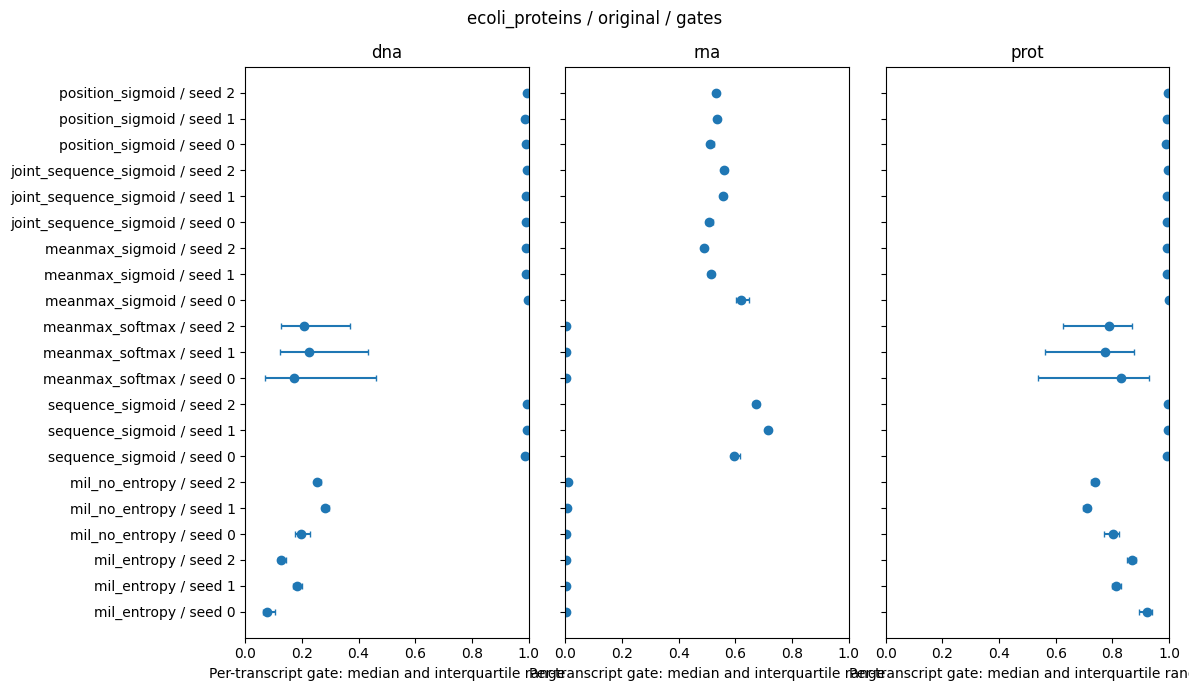

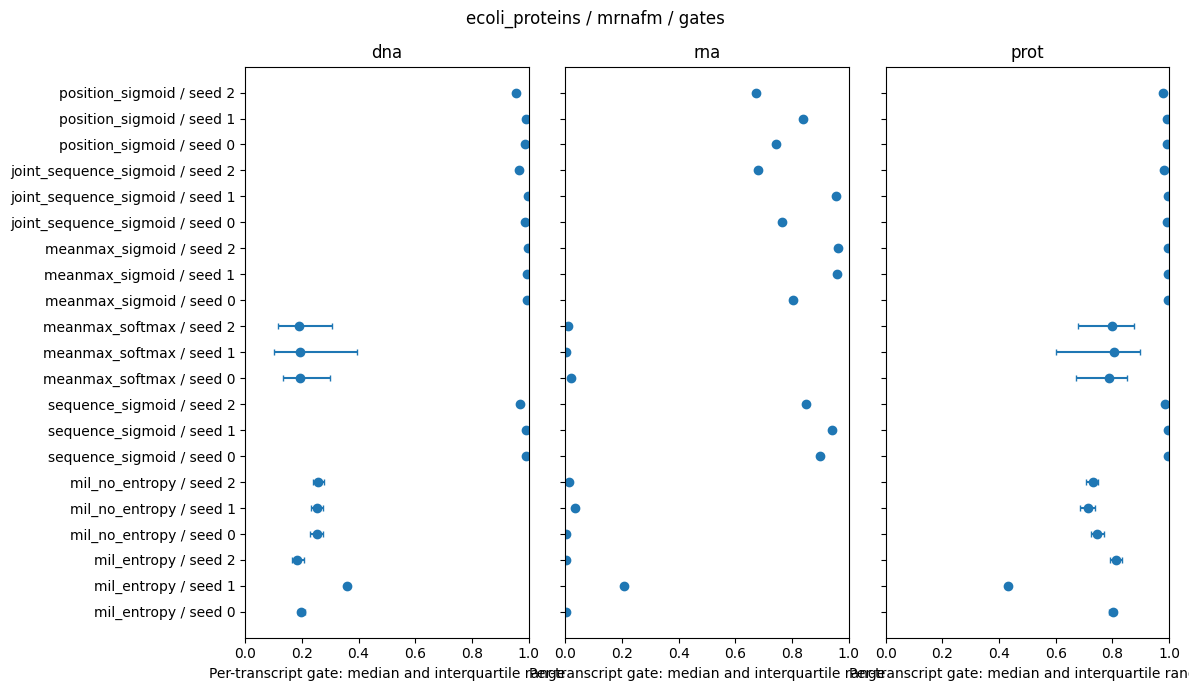

In [24]:
if gate_report is not None:
    gate_table = pd.DataFrame(gate_report["summary"])
    for (benchmark, bundle, quantity), group in gate_table.groupby(["benchmark", "bundle", "quantity"], sort=False):
        modalities = group["modality"].drop_duplicates().tolist()
        fig, axes = plt.subplots(1, len(modalities), figsize=(12, 7), sharey=True, squeeze=False)
        for ax, modality in zip(axes[0], modalities):
            rows = group.loc[group["modality"] == modality]
            labels = rows["model"] + " / seed " + rows["seed"].astype(str)
            ax.errorbar(rows["median"], labels,
                        xerr=[rows["median"] - rows["q25"], rows["q75"] - rows["median"]],
                        fmt="o", capsize=2)
            ax.set(title=modality, xlabel="Per-transcript gate: median and interquartile range", xlim=(0, 1))
        fig.suptitle(f"{benchmark} / {bundle} / {quantity}")
        fig.tight_layout()
        plt.show()

Within-transcript positional variation; median across transcripts, not an interval.


,benchmark,bundle,modality,model,quantity,seed,selected single modality,transcripts,within_row_range,within_row_sd
0,cov_vac_degradation,original,dna,position_sigmoid,gates,0,rna,400,0.005131,0.001252
1,cov_vac_degradation,original,rna,position_sigmoid,gates,0,rna,400,0.024278,0.005863
2,cov_vac_degradation,original,prot,position_sigmoid,gates,0,rna,400,0.013541,0.003254
3,cov_vac_degradation,original,dna,position_sigmoid,gates,1,rna,400,0.006028,0.001434
4,cov_vac_degradation,original,rna,position_sigmoid,gates,1,rna,400,0.035632,0.008827
5,cov_vac_degradation,original,prot,position_sigmoid,gates,1,rna,400,0.015235,0.003808
6,cov_vac_degradation,original,dna,position_sigmoid,gates,2,rna,400,0.004789,0.001158
7,cov_vac_degradation,original,rna,position_sigmoid,gates,2,rna,400,0.031233,0.007450
8,cov_vac_degradation,original,prot,position_sigmoid,gates,2,rna,400,0.017495,0.004348
9,cov_vac_degradation,mrnafm,dna,position_sigmoid,gates,0,prot,400,0.043574,0.008247


Sum of modality weights: sequence means, then transcript quartiles; sigmoid mass need not equal one.


,benchmark,bundle,median,model,q25,q75,quantity,seed,selected single modality,transcripts
0,cov_vac_degradation,original,1.000000,mil_entropy,1.000000,1.000000,gates,0,rna,400
1,cov_vac_degradation,original,1.000000,mil_entropy,1.000000,1.000000,gates,1,rna,400
2,cov_vac_degradation,original,1.000000,mil_entropy,1.000000,1.000000,gates,2,rna,400
3,cov_vac_degradation,original,1.000000,mil_no_entropy,1.000000,1.000000,gates,0,rna,400
4,cov_vac_degradation,original,1.000000,mil_no_entropy,1.000000,1.000000,gates,1,rna,400
...,...,...,...,...,...,...,...,...,...,...
79,ecoli_proteins,mrnafm,2.950378,joint_sequence_sigmoid,2.947047,2.953691,gates,1,rna,712
80,ecoli_proteins,mrnafm,2.627895,joint_sequence_sigmoid,2.619869,2.634746,gates,2,rna,712
81,ecoli_proteins,mrnafm,2.723240,position_sigmoid,2.717693,2.728688,gates,0,rna,712
82,ecoli_proteins,mrnafm,2.819652,position_sigmoid,2.814564,2.823917,gates,1,rna,712


Mean real-position Euclidean norms: transcript quartiles, not biological importance.


,benchmark,bundle,median,modality,model,q25,q75,quantity,seed,selected single modality,transcripts
0,cov_vac_degradation,original,3.620531,dna,mil_entropy,3.521005,3.741718,feature_norms,0,rna,400
1,cov_vac_degradation,original,7.324700,rna,mil_entropy,7.277209,7.375239,feature_norms,0,rna,400
2,cov_vac_degradation,original,4.938772,prot,mil_entropy,4.886990,5.047004,feature_norms,0,rna,400
3,cov_vac_degradation,original,3.016287,dna,mil_entropy,2.868436,3.130043,contribution_norms,0,rna,400
4,cov_vac_degradation,original,0.045545,rna,mil_entropy,0.041995,0.049606,contribution_norms,0,rna,400
...,...,...,...,...,...,...,...,...,...,...,...
583,ecoli_proteins,mrnafm,5.295249,prot,position_sigmoid,5.040995,5.589066,feature_norms,2,rna,712
584,ecoli_proteins,mrnafm,3.364135,dna,position_sigmoid,3.333807,3.402549,contribution_norms,2,rna,712
585,ecoli_proteins,mrnafm,5.522624,rna,position_sigmoid,5.419594,5.615856,contribution_norms,2,rna,712
586,ecoli_proteins,mrnafm,5.176276,prot,position_sigmoid,4.929611,5.466234,contribution_norms,2,rna,712


Attention update / anchor norm: within-transcript ratios, then transcript quartiles.
Unavailable in this saved report; no inference or analysis started.
Recorded norm availability and softmax temperature.


,benchmark,bundle,model,norm status,seed,selected single modality,temperature
0,cov_vac_degradation,original,mil_entropy,recorded,0,rna,0.987457
1,cov_vac_degradation,original,mil_entropy,recorded,1,rna,0.985277
2,cov_vac_degradation,original,mil_entropy,recorded,2,rna,0.982984
3,cov_vac_degradation,original,mil_no_entropy,recorded,0,rna,0.990066
4,cov_vac_degradation,original,mil_no_entropy,recorded,1,rna,0.989527
...,...,...,...,...,...,...,...
79,ecoli_proteins,mrnafm,joint_sequence_sigmoid,recorded,1,rna,NaN
80,ecoli_proteins,mrnafm,joint_sequence_sigmoid,recorded,2,rna,NaN
81,ecoli_proteins,mrnafm,position_sigmoid,recorded,0,rna,NaN
82,ecoli_proteins,mrnafm,position_sigmoid,recorded,1,rna,NaN


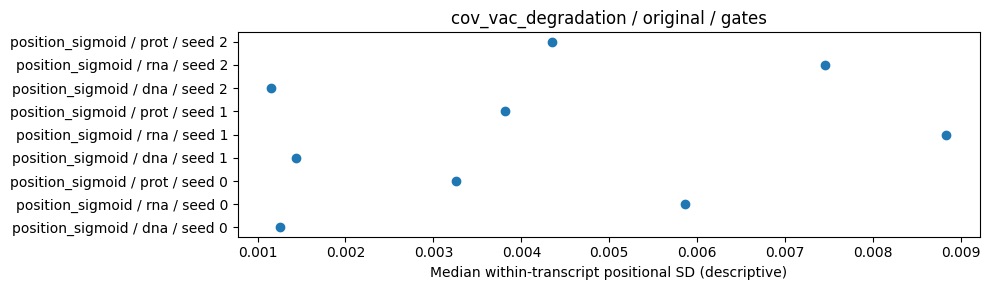

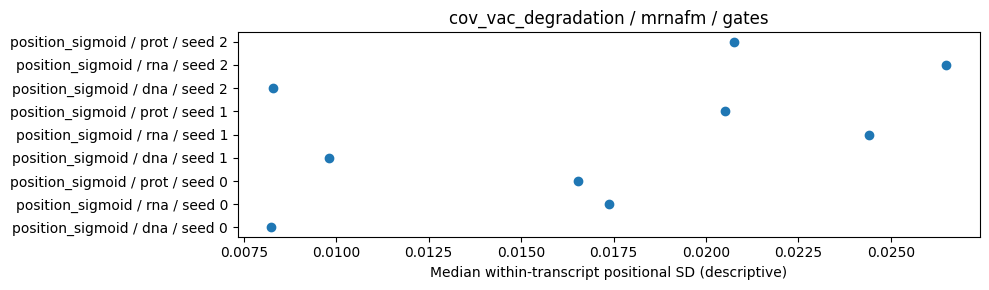

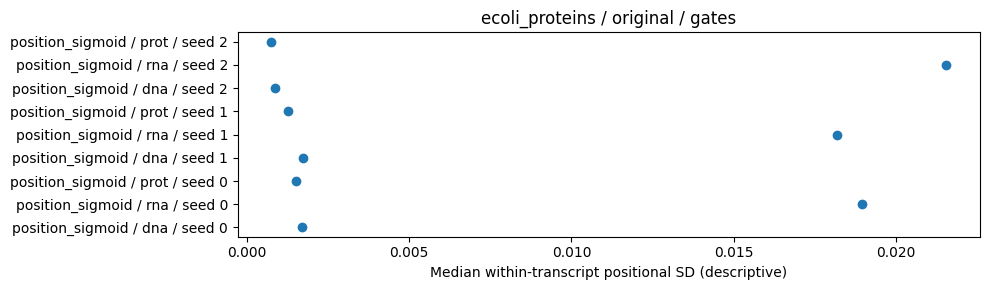

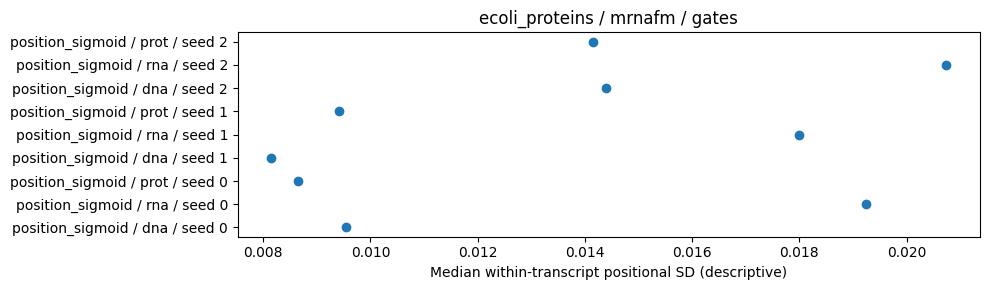

In [25]:
if gate_report is not None:
    for key, explanation in (
        ("positional_variation", "Within-transcript positional variation; median across transcripts, not an interval."),
        ("weight_mass", "Sum of modality weights: sequence means, then transcript quartiles; sigmoid mass need not equal one."),
        ("norm_summary", "Mean real-position Euclidean norms: transcript quartiles, not biological importance."),
        ("update_anchor_ratios", "Attention update / anchor norm: within-transcript ratios, then transcript quartiles."),
        ("diagnostic_status", "Recorded norm availability and softmax temperature."),
    ):
        print(explanation)
        rows = gate_report.get(key, [])
        if rows:
            display(pd.DataFrame(rows))
        else:
            print("Unavailable in this saved report; no inference or analysis started.")
    variation = pd.DataFrame(gate_report.get("positional_variation", []))
    if not variation.empty:
        for (benchmark, bundle, quantity), rows in variation.groupby(["benchmark", "bundle", "quantity"], sort=False):
            fig, ax = plt.subplots(figsize=(10, max(3, len(rows) * .2)))
            labels = rows["model"] + " / " + rows["modality"] + " / seed " + rows["seed"].astype(str)
            ax.scatter(rows["within_row_sd"], labels)
            ax.set(title=f"{benchmark} / {bundle} / {quantity}",
                   xlabel="Median within-transcript positional SD (descriptive)")
            fig.tight_layout()
            plt.show()


---

## What this can establish

On CoV-Vac, the position-wise gate exceeded the similarly sized nongated residual control by 0.024 Spearman with the original encoders and 0.026 with the mRNA-FM replacement. Both paired 95% intervals were above zero. When the comparator was the **matched sequence-level gate**, all four intervals included zero across both benchmarks and both encoder combinations. The CoV-Vac gain over the nongated control therefore gives little evidence that varying weights by position supplied the benefit.

Removing the entropy penalty from MIL also gave intervals spanning zero in all four settings. Gate weights and contribution norms can suggest which inputs to perturb next. Establishing that a modality supplied unique biological information would require additional controls. [Continue to the anchor-attention experiment](anchor_cross_attention.ipynb)